#1. Forecasting Preparation


The final output contains the forecast month, product family, selected model, and predicted sales.

##1.1 Objective

This notebook generates monthly sales forecasts for each product family for August, September, and October 2017.

The forecasting models are selected based on the rolling-origin evaluation results from the model development notebook. Each product family uses its selected model, which is retrained using the available historical data through July 2017.


## 1.2 Data Loading and Preparation

This section loads the processed monthly sales data and the selected forecasting model for each product family. The data will be used to retrain the selected models and generate forecasts for the next three months.


In [1]:
from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
from pathlib import Path

project_dir = Path(
    '/content/drive/MyDrive/retail-sales-forecasting'
)

processed_dir = project_dir / 'data' / 'processed'

modeling_data = pd.read_csv(
    processed_dir / 'monthly_sales.csv',
    parse_dates=['date']
)

selected_models = pd.read_csv(
    processed_dir / 'selected_models_per_family.csv'
)

modeling_data['month'] = pd.PeriodIndex(
    modeling_data['month'],
    freq='M'
)

print('Modeling data shape:', modeling_data.shape)
print('Selected models shape:', selected_models.shape)

print('\nModeling data preview:')
display(modeling_data.head())

print('\nSelected models preview:')
display(selected_models.head())

print(
    '\nNumber of unique families in modeling data:',
    modeling_data['family'].nunique()
)

print(
    'Number of selected families:',
    selected_models['family'].nunique()
)

Modeling data shape: (1815, 4)
Selected models shape: (33, 9)

Modeling data preview:


,month,date,family,sales
0,2013-01,2013-01-01,AUTOMOTIVE,6557.0
1,2013-02,2013-02-01,AUTOMOTIVE,7220.0
2,2013-03,2013-03-01,AUTOMOTIVE,7635.0
3,2013-04,2013-04-01,AUTOMOTIVE,7485.0
4,2013-05,2013-05-01,AUTOMOTIVE,9034.0



Selected models preview:


,family,model,MAE,RMSE,WAPE (%),MAE_rank,RMSE_rank,WAPE (%)_rank,average_rank
0,AUTOMOTIVE,Seasonal Naive,870.400000,1107.479842,7.078034,1.0,3.0,1.0,1.666667
1,BABY CARE,Naive,80.533333,104.245224,22.503726,1.0,1.0,1.0,1.000000
2,BEAUTY,Seasonal Naive,1313.933333,1619.142798,15.521097,1.0,1.0,1.0,1.000000
3,BEVERAGES,Naive,426214.333333,568495.260252,7.278941,1.0,1.0,1.0,1.000000
4,BOOKS,Naive,303.733333,333.681085,97.267293,1.0,1.0,1.0,1.000000



Number of unique families in modeling data: 33
Number of selected families: 33


## 1.3 Data Validation

Before retraining the selected forecasting models, the historical data and model selection results are validated. This step checks the date range, missing values, duplicate family-month combinations, and consistency of product families between the sales data and the selected model list.

These checks help ensure that all product families have valid historical data and a corresponding selected forecasting model.

In [3]:
print('Date range:')
print('Start:', modeling_data['month'].min())
print('End:', modeling_data['month'].max())

Date range:
Start: 2013-01
End: 2017-07


In [4]:
print('\nMissing values:')
print(modeling_data.isna().sum())



Missing values:
month     0
date      0
family    0
sales     0
dtype: int64


In [5]:
print('\nDuplicate family-month combinations:')
print(
    modeling_data.duplicated(
        subset=['month', 'family']
    ).sum()
)


Duplicate family-month combinations:
0


In [6]:
print('\nFamily consistency:')
print(
    'Families in sales data:',
    modeling_data['family'].nunique()
)
print(
    'Families in selected models:',
    selected_models['family'].nunique()
)


Family consistency:
Families in sales data: 33
Families in selected models: 33


In [7]:
print('\nMissing model selections:')
missing_models = set(modeling_data['family']) - set(
    selected_models['family']
)
print(missing_models)


Missing model selections:
set()


In [8]:
print('\nUnexpected selected families:')
extra_models = set(selected_models['family']) - set(
    modeling_data['family']
)
print(extra_models)


Unexpected selected families:
set()


In [9]:
print('\nMonthly records per family:')
print(
    modeling_data.groupby('family')['month'].nunique()
    .value_counts()
    .sort_index()
)


Monthly records per family:
month
55    33
Name: count, dtype: int64


## 1.4 Forecasting Strategy

Each product family will use the forecasting model selected during the model evaluation stage. The selected models are retrained using the available monthly sales data from January 2013 through July 2017.

The forecast horizon consists of three consecutive months: August, September, and October 2017. Naive and Seasonal Naive forecasts will be generated using their respective historical rules, while Random Forest Lag 12 will use a recursive forecasting approach in which previous predictions become inputs for subsequent forecast months.

The final output will contain 99 forecasts, covering 33 product families across three months.

## 1.5 Preparing Historical Features and Training Data

This section prepares historical sales features for the Random Forest Lag 12 model and constructs the training dataset. The features include the month number, time index, previous monthly sales, sales from the same month in the previous year, and the three-month rolling average.

Rows with incomplete historical features are excluded from the training dataset. The training data is limited to observations available through July 2017 to ensure that the final forecasting process uses only historical information.

In [10]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Define the forecast period
forecast_origin = pd.Period('2017-07', freq='M')
forecast_horizon = 3

forecast_months = pd.period_range(
    start=forecast_origin + 1,
    periods=forecast_horizon,
    freq='M'
)

print('Forecast origin:', forecast_origin)
print('Forecast horizon:', forecast_horizon, 'months')
print('Forecast months:', list(forecast_months))

Forecast origin: 2017-07
Forecast horizon: 3 months
Forecast months: [Period('2017-08', 'M'), Period('2017-09', 'M'), Period('2017-10', 'M')]


In [11]:
feature_data = modeling_data.copy()

feature_data = feature_data.sort_values(
    ['family', 'date']
).reset_index(drop=True)

feature_data['month_number'] = feature_data['date'].dt.month

feature_data['time_index'] = (
    (feature_data['date'].dt.year - 2013) * 12
    + feature_data['date'].dt.month
)

for lag in [1, 2, 3, 12]:
    feature_data[f'lag_{lag}'] = (
        feature_data.groupby('family')['sales'].shift(lag)
    )

feature_data['rolling_mean_3'] = (
    feature_data.groupby('family')['sales']
    .transform(
        lambda sales: sales.shift(1).rolling(
            window=3,
            min_periods=3
        ).mean()
    )
)

display(feature_data.tail())


,month,date,family,sales,month_number,time_index,lag_1,lag_2,lag_3,lag_12,rolling_mean_3
1810,2017-03,2017-03-01,SEAFOOD,41956.981018,3,51,33861.813997,37421.704073,32011.248001,39254.808992,34431.588690
1811,2017-04,2017-04-01,SEAFOOD,36221.881986,4,52,41956.981018,33861.813997,37421.704073,39353.467045,37746.833029
1812,2017-05,2017-05-01,SEAFOOD,39666.393999,5,53,36221.881986,41956.981018,33861.813997,40018.643985,37346.892334
1813,2017-06,2017-06-01,SEAFOOD,31365.775991,6,54,39666.393999,36221.881986,41956.981018,36849.899012,39281.752334
1814,2017-07,2017-07-01,SEAFOOD,35040.687006,7,55,31365.775991,39666.393999,36221.881986,39440.733051,35751.350658


In [12]:
print('Feature data shape:', feature_data.shape)
print('\nMissing values in lag features:')
display(
    feature_data[
        ['lag_1', 'lag_2', 'lag_3', 'lag_12', 'rolling_mean_3']
    ].isna().sum()
)

Feature data shape: (1815, 11)

Missing values in lag features:


,0
lag_1,33
lag_2,66
lag_3,99
lag_12,396
rolling_mean_3,99


In [13]:
rf_features = [
    'family',
    'month_number',
    'time_index',
    'lag_1',
    'lag_2',
    'lag_3',
    'lag_12',
    'rolling_mean_3'
]

training_data = feature_data.dropna(
    subset=rf_features
).copy()

training_data = training_data.loc[
    training_data['month'] <= pd.Period('2017-07', freq='M')
].copy()

print('Training data shape:', training_data.shape)
print('Date range:', training_data['month'].min(), 'to', training_data['month'].max())
print('Number of product families:', training_data['family'].nunique())
print('Missing values in selected features:', training_data[rf_features].isna().sum().sum())

display(training_data.head())

Training data shape: (1419, 11)
Date range: 2014-01 to 2017-07
Number of product families: 33
Missing values in selected features: 0


,month,date,family,sales,month_number,time_index,lag_1,lag_2,lag_3,lag_12,rolling_mean_3
12,2014-01,2014-01-01,AUTOMOTIVE,8491.0,1,13,8411.0,7166.0,6803.0,6557.0,7460.000000
13,2014-02,2014-02-01,AUTOMOTIVE,7563.0,2,14,8491.0,8411.0,7166.0,7220.0,8022.666667
14,2014-03,2014-03-01,AUTOMOTIVE,10115.0,3,15,7563.0,8491.0,8411.0,7635.0,8155.000000
15,2014-04,2014-04-01,AUTOMOTIVE,8426.0,4,16,10115.0,7563.0,8491.0,7485.0,8723.000000
16,2014-05,2014-05-01,AUTOMOTIVE,8075.0,5,17,8426.0,10115.0,7563.0,9034.0,8701.333333


# 2. Final Forecasting

This section generates monthly sales forecasts for August, September, and October 2017 for all 33 product families. The forecasting process follows the model selection results from the model evaluation stage.

Each product family uses its selected model: Naive, Seasonal Naive, or Random Forest Lag 12. The final forecasts are generated using historical sales data available through July 2017.

## 2.1 Fitting the Final Model

This section fits the Random Forest Lag 12 model using the prepared training data. The model uses historical sales features, including recent sales values and sales from the same month in the previous year, to learn patterns across product families.

The trained model will be used to forecast product families assigned to Random Forest Lag 12. Product families assigned to Naive or Seasonal Naive will use their respective forecasting rules.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

categorical_features = ['family']

numeric_features_lag12 = [
    'month_number',
    'time_index',
    'lag_1',
    'lag_2',
    'lag_3',
    'lag_12',
    'rolling_mean_3'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'family_encoder',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numeric_features',
            'passthrough',
            numeric_features_lag12
        )
    ]
)

final_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'regressor',
            RandomForestRegressor(
                n_estimators=200,
                max_depth=None,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

final_model.fit(
    training_data[
        categorical_features + numeric_features_lag12
    ],
    training_data['sales']
)

print('Final Random Forest Lag 12 model fitted successfully.')
print('Training observations:', len(training_data))
print('Product families:', training_data['family'].nunique())
print(
    'Training period:',
    training_data['month'].min(),
    'to',
    training_data['month'].max()
)

Final Random Forest Lag 12 model fitted successfully.
Training observations: 1419
Product families: 33
Training period: 2014-01 to 2017-07


## 2.2 Generating Final Forecasts

This section generates monthly sales forecasts for August, September, and October 2017 using the selected model for each product family. Naive forecasts use the latest observed sales, Seasonal Naive forecasts use sales from the corresponding month in the previous year, and Random Forest Lag 12 forecasts use recursively updated historical features.

All forecasts are based on observed sales data available through July 2017. Predicted sales are constrained to non-negative values.

In [15]:
import numpy as np
import pandas as pd

forecast_months = pd.period_range(
    start='2017-08',
    end='2017-10',
    freq='M'
)

forecast_origin = pd.Period('2017-07', freq='M')
forecast_results = []

for family in sorted(modeling_data['family'].unique()):

    family_history = (
        modeling_data.loc[
            (modeling_data['family'] == family)
            & (modeling_data['month'] <= forecast_origin)
        ]
        .sort_values('month')
    )

    sales_history = family_history['sales'].tolist()

    selected_model = selected_models.loc[
        selected_models['family'] == family,
        'model'
    ].iloc[0]

    for target_month in forecast_months:

        if selected_model == 'Naive':
            predicted_sales = sales_history[-1]

        elif selected_model == 'Seasonal Naive':
            seasonal_month = target_month - 12

            seasonal_value = family_history.loc[
                family_history['month'] == seasonal_month,
                'sales'
            ]

            if seasonal_value.empty:
                raise ValueError(
                    f'Missing seasonal history for {family}, '
                    f'{target_month}'
                )

            predicted_sales = float(seasonal_value.iloc[0])

        elif selected_model == 'Random Forest Lag 12':

            feature_row = pd.DataFrame([{
                'family': family,
                'month_number': target_month.month,
                'time_index': (
                    (target_month.year - 2013) * 12
                    + target_month.month
                ),
                'lag_1': sales_history[-1],
                'lag_2': sales_history[-2],
                'lag_3': sales_history[-3],
                'lag_12': sales_history[-12],
                'rolling_mean_3': np.mean(sales_history[-3:])
            }])

            predicted_sales = float(
                final_model.predict(
                    feature_row[
                        categorical_features
                        + numeric_features_lag12
                    ]
                )[0]
            )

            # Update history for recursive forecasting
            sales_history.append(max(0, predicted_sales))

        else:
            raise ValueError(
                f'Unknown model for {family}: {selected_model}'
            )

        predicted_sales = max(0, predicted_sales)

        forecast_results.append({
            'month': str(target_month),
            'family': family,
            'selected_model': selected_model,
            'predicted_sales': predicted_sales
        })

forecast_df = pd.DataFrame(forecast_results)

print('Forecast shape:', forecast_df.shape)
print('Forecast months:', sorted(forecast_df['month'].unique()))
print('Product families:', forecast_df['family'].nunique())
print(
    'Missing predictions:',
    forecast_df['predicted_sales'].isna().sum()
)

display(forecast_df.head(10))

Forecast shape: (99, 4)
Forecast months: ['2017-08', '2017-09', '2017-10']
Product families: 33
Missing predictions: 0


,month,family,selected_model,predicted_sales
0,2017-08,AUTOMOTIVE,Seasonal Naive,10792.0
1,2017-09,AUTOMOTIVE,Seasonal Naive,9058.0
2,2017-10,AUTOMOTIVE,Seasonal Naive,10728.0
3,2017-08,BABY CARE,Naive,351.0
4,2017-09,BABY CARE,Naive,351.0
5,2017-10,BABY CARE,Naive,351.0
6,2017-08,BEAUTY,Seasonal Naive,8774.0
7,2017-09,BEAUTY,Seasonal Naive,8284.0
8,2017-10,BEAUTY,Seasonal Naive,9634.0
9,2017-08,BEVERAGES,Naive,6204055.0


#3. Forecast Results and Export

This section validates and interprets the final sales forecasts before exporting the results. The forecasts are checked for completeness, non-negative values, and consistency across product families and forecast months. Summary statistics are also examined to understand the distribution of predicted sales.

## 3.1 Forecast Validation and Interpretation

This section checks the completeness and consistency of the forecast results. It verifies that all 33 product families have predictions for August, September, and October 2017, with no missing or negative forecast values.

Summary statistics are then used to examine the predicted sales across product families and forecast months.

In [16]:
expected_rows = 33 * 3

print('Total forecast rows:', len(forecast_df))
print('Expected forecast rows:', expected_rows)
print('Unique product families:', forecast_df['family'].nunique())
print('Unique forecast months:', forecast_df['month'].nunique())
print('Missing predictions:', forecast_df['predicted_sales'].isna().sum())
print('Negative predictions:', (forecast_df['predicted_sales'] < 0).sum())
print(
    'Duplicate family-month combinations:',
    forecast_df.duplicated(subset=['family', 'month']).sum()
)

assert len(forecast_df) == expected_rows
assert forecast_df['family'].nunique() == 33
assert forecast_df['month'].nunique() == 3
assert forecast_df['predicted_sales'].notna().all()
assert (forecast_df['predicted_sales'] >= 0).all()
assert not forecast_df.duplicated(
    subset=['family', 'month']
).any()

print('\nAll forecast validation checks passed.')

print('\nForecast summary by month:')
display(
    forecast_df.groupby('month')['predicted_sales']
    .agg(['sum', 'mean', 'min', 'max'])
    .round(2)
)

Total forecast rows: 99
Expected forecast rows: 99
Unique product families: 33
Unique forecast months: 3
Missing predictions: 0
Negative predictions: 0
Duplicate family-month combinations: 0

All forecast validation checks passed.

Forecast summary by month:


,sum,mean,min,max
month,,,,
2017-08,25599629.81,775746.36,46.0,7263668.22
2017-09,25522851.08,773419.73,46.0,7172561.52
2017-10,26447360.62,801435.17,46.0,7709438.94


## 3.2 Exporting Forecast Results

The validated forecasts are exported to a CSV file for further analysis, visualization, and portfolio presentation. The output contains the forecast month, product family, selected model, and predicted sales.

The exported file can be used to create visualizations and communicate the expected sales patterns for August to October 2017.

In [17]:
output_path = processed_dir / 'final_sales_forecast_aug_oct_2017.csv'

forecast_df.to_csv(output_path, index=False)

print('Forecast results exported successfully.')
print('Saved to:', output_path)
print('Exported rows:', len(forecast_df))

display(forecast_df.head())

Forecast results exported successfully.
Saved to: /content/drive/MyDrive/retail-sales-forecasting/data/processed/final_sales_forecast_aug_oct_2017.csv
Exported rows: 99


,month,family,selected_model,predicted_sales
0,2017-08,AUTOMOTIVE,Seasonal Naive,10792.0
1,2017-09,AUTOMOTIVE,Seasonal Naive,9058.0
2,2017-10,AUTOMOTIVE,Seasonal Naive,10728.0
3,2017-08,BABY CARE,Naive,351.0
4,2017-09,BABY CARE,Naive,351.0


## 3.3 Conclusion

The final forecasting process generated 99 monthly sales predictions for 33 product families from August to October 2017. Each product family was forecast using the model selected during the model evaluation stage: Naive, Seasonal Naive, or Random Forest Lag 12.

The forecast results passed the validation checks, with no missing predictions, negative values, or duplicate family-month combinations. The results were exported to a CSV file for further analysis and visualization.

These forecasts provide an overview of expected sales patterns across product families. However, the predictions should be interpreted as estimates rather than actual sales, and their accuracy cannot be confirmed without comparing them against the corresponding actual sales data.

## 3.4 Visualizing Forecast Results

This section visualizes the final sales forecasts to make the results easier to interpret. The first visualization shows the total predicted sales across all product families for each forecast month from August to October 2017.

The chart helps identify changes in the overall forecast across the three-month forecasting period.

In [18]:
import matplotlib.pyplot as plt

figures_dir = project_dir / 'reports' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)

print('Figures directory:', figures_dir)

Figures directory: /content/drive/MyDrive/retail-sales-forecasting/reports/figures


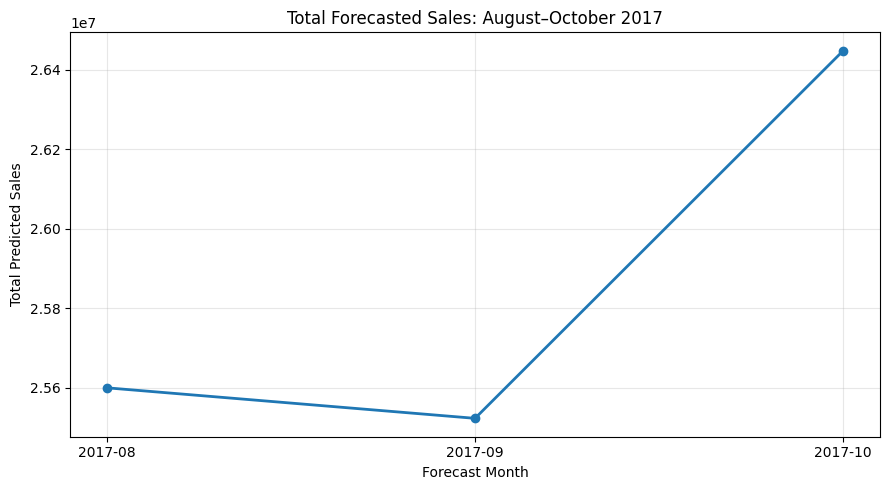

Saved: /content/drive/MyDrive/retail-sales-forecasting/reports/figures/total_monthly_forecast.png


In [19]:
# Save the total monthly forecast chart

monthly_forecast = (
    forecast_df.groupby('month')['predicted_sales']
    .sum()
    .reset_index()
)

plt.figure(figsize=(9, 5))

plt.plot(
    monthly_forecast['month'],
    monthly_forecast['predicted_sales'],
    marker='o',
    linewidth=2
)

plt.title('Total Forecasted Sales: August–October 2017')
plt.xlabel('Forecast Month')
plt.ylabel('Total Predicted Sales')
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / 'total_monthly_forecast.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print('Saved:', figures_dir / 'total_monthly_forecast.png')

**Total Forecasted Sales: August–October 2017**


---


**Interpretation**

The total forecasted sales decrease slightly from approximately 25.60 million in August to 25.52 million in September 2017. In October, the forecast increases to approximately 26.45 million, representing the highest predicted total across the three-month forecasting period.

This pattern suggests a slight decline in predicted sales in September, followed by an increase in October. However, these values represent model forecasts rather than actual sales, so the observed pattern should be interpreted as an expected trend rather than a confirmed outcome.


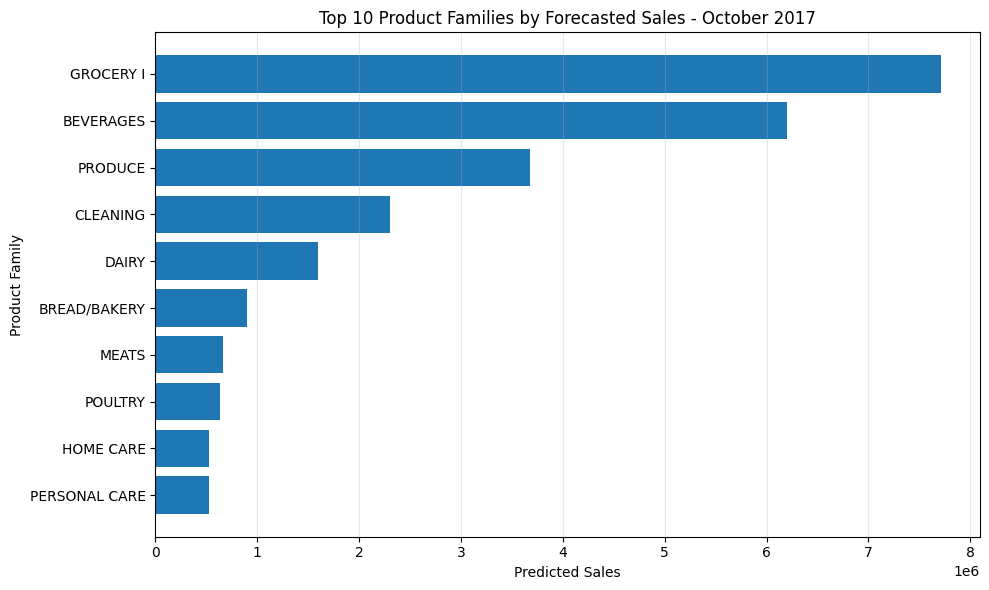

Saved: /content/drive/MyDrive/retail-sales-forecasting/reports/figures/top_10_product_families.png


In [22]:
# Save the top 10 product families chart
october_forecast = forecast_df.loc[
    forecast_df['month'] == '2017-10'
].copy()

top_10_families = (
    october_forecast
    .sort_values('predicted_sales', ascending=False)
    .head(10)
    .sort_values('predicted_sales', ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_families['family'],
    top_10_families['predicted_sales']
)

plt.title('Top 10 Product Families by Forecasted Sales - October 2017')
plt.xlabel('Predicted Sales')
plt.ylabel('Product Family')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / 'top_10_product_families.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print('Saved:', figures_dir / 'top_10_product_families.png')

**Top 10 Product Families by Forecasted Sales, October
2017**



---


**Interpretation**

The forecast shows that GROCERY I has the highest predicted sales for October 2017, followed by BEVERAGES and PRODUCE. These product families are expected to contribute substantially to the total forecasted sales.

The difference between the top product families and the remaining categories indicates that predicted sales volumes vary considerably across product families. This highlights the importance of evaluating sales patterns at the product-family level rather than relying solely on aggregate forecasts.

These rankings are based on predicted sales for October 2017 and should not be interpreted as confirmed sales performance.


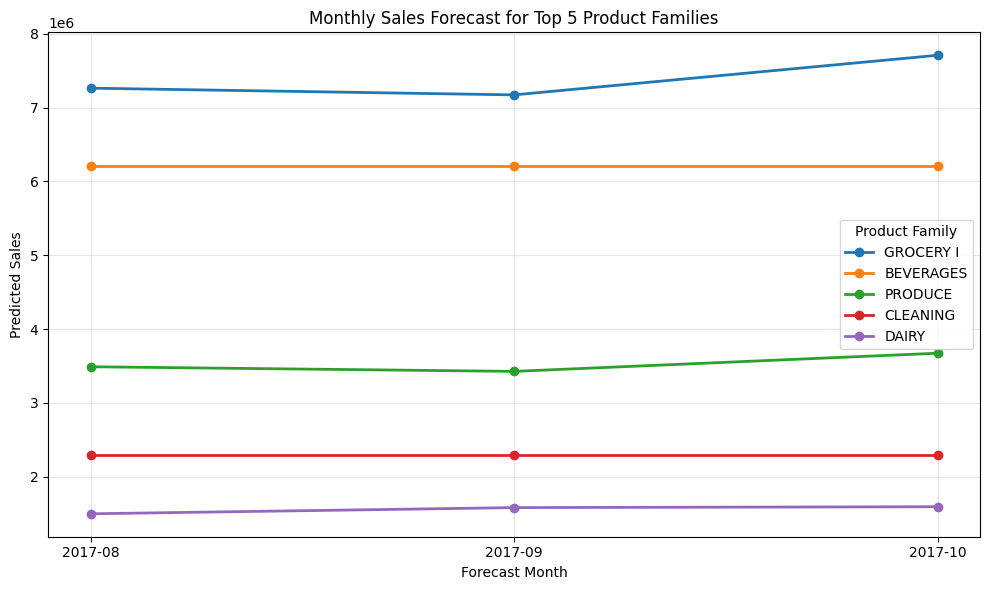

Saved: /content/drive/MyDrive/retail-sales-forecasting/reports/figures/top_5_families_monthly_forecast.png


In [23]:
# Save the monthly forecast comparison chart
top_5_families = (
    october_forecast
    .nlargest(5, 'predicted_sales')['family']
    .tolist()
)

top_5_forecast = forecast_df.loc[
    forecast_df['family'].isin(top_5_families)
].copy()

forecast_pivot = top_5_forecast.pivot(
    index='month',
    columns='family',
    values='predicted_sales'
)

plt.figure(figsize=(10, 6))

for family in top_5_families:
    plt.plot(
        forecast_pivot.index,
        forecast_pivot[family],
        marker='o',
        linewidth=2,
        label=family
    )

plt.title('Monthly Sales Forecast for Top 5 Product Families')
plt.xlabel('Forecast Month')
plt.ylabel('Predicted Sales')
plt.legend(title='Product Family')
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / 'top_5_families_monthly_forecast.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print(
    'Saved:',
    figures_dir / 'top_5_families_monthly_forecast.png'
)

**Monthly Sales Forecast for Top 5 Product Families.**


---


**Interpretation**

The monthly forecasts show different patterns across the five product families with the highest predicted sales in October 2017. GROCERY I and PRODUCE show a slight decrease in September, followed by an increase in October. BEVERAGES and CLEANING remain relatively stable throughout the forecast period, while DAIRY shows a small increase followed by relatively stable predictions.

These differences reflect the forecasting behavior of the selected models for each product family. For example, a flat forecast may result from the Naive method, which uses the latest observed sales value for subsequent forecast months.

The results illustrate why forecasting patterns should be examined at the product-family level, as aggregate forecasts may hide differences between individual categories. All values remain predictions and should not be treated as actual sales.
